# Pneumonia Detection from Chest X-Rays using a CNN

**Dataset:** Chest X-Ray Images (Pneumonia), Kaggle
https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia

The goal is to classify a chest X-ray as **NORMAL** or **PNEUMONIA**, so it can be used as a screening tool
to help doctors prioritise which scans to look at first.

In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

np.random.seed(42)
tf.random.set_seed(42)
print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPU: []


## 1. Loading the data

In [2]:
# folder that has train, val and test inside it
base_dir = r'D:\Downloads\chest x rays images (Pneumonia)\chest_xray'

# some copies of this dataset have another chest_xray folder inside, so check for that
if not os.path.isdir(os.path.join(base_dir, 'train')):
    base_dir = os.path.join(base_dir, 'chest_xray')
print('Using:', base_dir)

CLASSES = ['NORMAL', 'PNEUMONIA']

def get_files(split):
    paths, labels = [], []
    for label, cls in enumerate(CLASSES):
        for ext in ('*.jpeg', '*.jpg', '*.png'):
            files = glob.glob(os.path.join(base_dir, split, cls, ext))
            paths += files
            labels += [label] * len(files)
    return pd.DataFrame({'path': paths, 'label': labels})

train_df = get_files('train')
val_df = get_files('val')
test_df = get_files('test')

for name, d in [('train', train_df), ('val', val_df), ('test', test_df)]:
    print(name, len(d), d['label'].value_counts().to_dict())

Using: D:\Downloads\chest x rays images (Pneumonia)\chest_xray
train 5216 {1: 3875, 0: 1341}
val 16 {0: 8, 1: 8}
test 624 {1: 390, 0: 234}


The given validation folder only has 16 images, which is too small to be useful. So I merge it with the
training images and make my own stratified 80/20 train/validation split. The test folder is kept untouched.

In [3]:
full_df = pd.concat([train_df, val_df], ignore_index=True)
train_df, val_df = train_test_split(full_df, test_size=0.2, stratify=full_df['label'], random_state=42)

print('Train:', len(train_df), train_df['label'].value_counts().to_dict())
print('Val  :', len(val_df), val_df['label'].value_counts().to_dict())
print('Test :', len(test_df), test_df['label'].value_counts().to_dict())

Train: 4185 {1: 3106, 0: 1079}
Val  : 1047 {1: 777, 0: 270}
Test : 624 {1: 390, 0: 234}


## 2. Exploratory Data Analysis

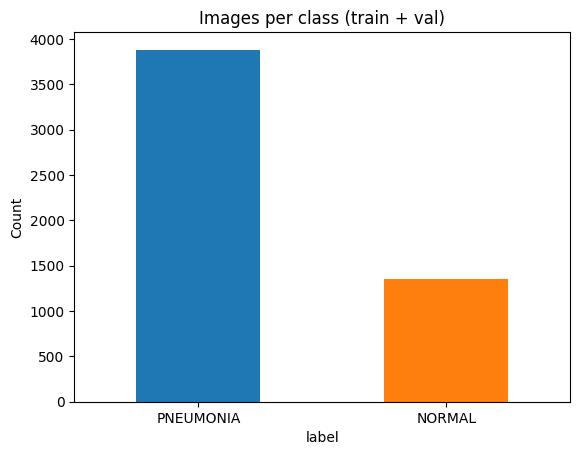

In [4]:
counts = full_df['label'].map({0: 'NORMAL', 1: 'PNEUMONIA'}).value_counts()
counts.plot(kind='bar', color=['tab:blue', 'tab:orange'])
plt.title('Images per class (train + val)')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

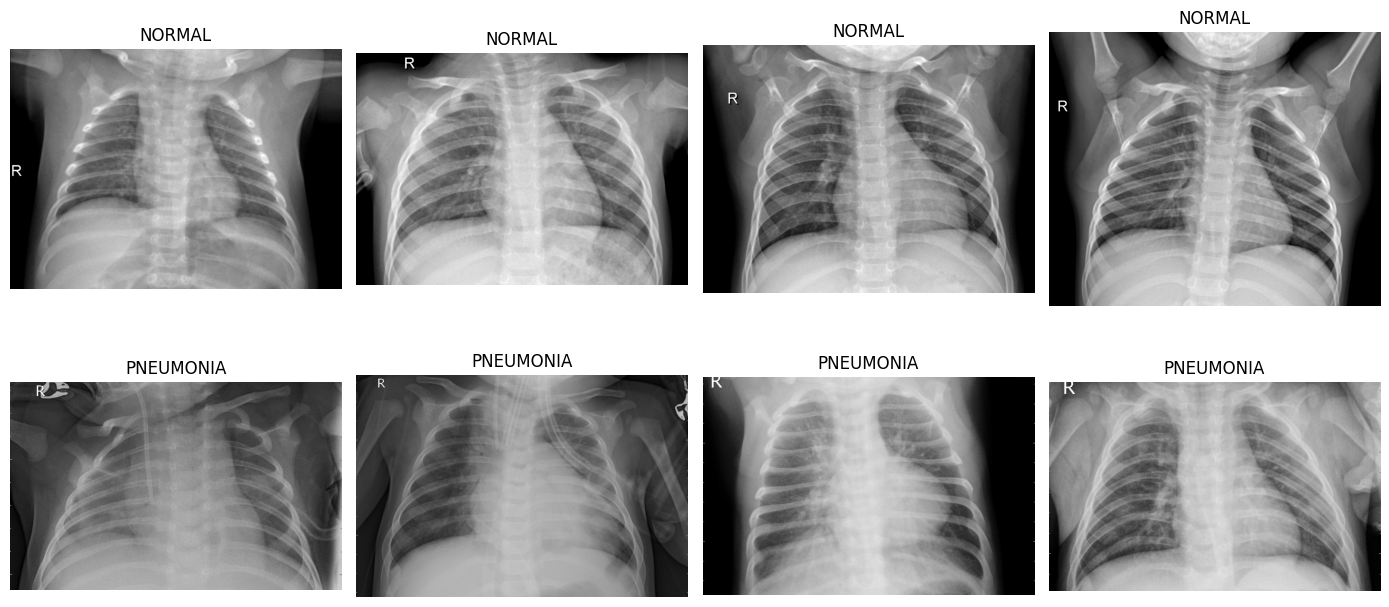

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for row, label in enumerate([0, 1]):
    samples = full_df[full_df['label'] == label].sample(4, random_state=1)['path'].values
    for col, p in enumerate(samples):
        img = plt.imread(p)
        axes[row, col].imshow(img, cmap='gray')
        axes[row, col].set_title(CLASSES[label])
        axes[row, col].axis('off')
plt.tight_layout()
plt.show()

In [6]:
# the images come in different sizes, so they need to be resized
sizes = [plt.imread(p).shape[:2] for p in full_df['path'].sample(200, random_state=0)]
sizes = np.array(sizes)
print('Height range:', sizes[:, 0].min(), '-', sizes[:, 0].max())
print('Width range :', sizes[:, 1].min(), '-', sizes[:, 1].max())

Height range: 156 - 2543
Width range : 469 - 2510


## 3. Data Preprocessing

In [7]:
IMG_SIZE = 180
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=1)   # x-rays are grayscale, some files are saved as RGB
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = img / 255.0
    return img, label

def make_dataset(df, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((df['path'].values, df['label'].values.astype('float32')))
    if shuffle:
        ds = ds.shuffle(len(df), seed=42)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_df, shuffle=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

In [9]:
# pneumonia images are about 3x more than normal ones, so use class weights
weights = compute_class_weight('balanced', classes=np.array([0, 1]), y=train_df['label'].values)
class_weights = {0: weights[0], 1: weights[1]}
print(class_weights)

{0: np.float64(1.9392956441149212), 1: np.float64(0.6736960721184804)}


Data augmentation is done inside the model so it only runs during training. I used small rotations, zoom and
shifts. I did **not** use horizontal flipping because in a real chest X-ray the heart is always on one side,
so a flipped image is not realistic.

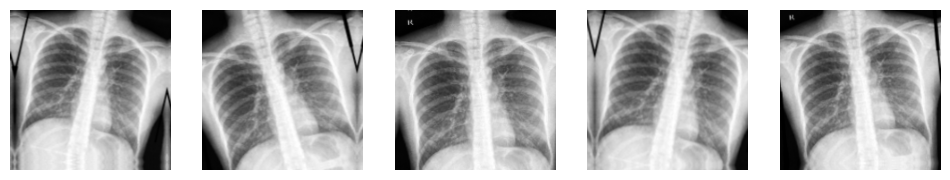

In [8]:
augment = keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.05, 0.05),
], name='augmentation')

# check what the augmentation looks like
img, _ = next(iter(train_ds.unbatch().take(1)))
plt.figure(figsize=(12, 3))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(augment(tf.expand_dims(img, 0), training=True)[0, :, :, 0], cmap='gray')
    plt.axis('off')
plt.show()

## 4. Model Architecture

In [10]:
def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(filters, 3, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D()(x)
    return x

def build_cnn():
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 1))
    x = augment(inputs)
    x = conv_block(x, 32)
    x = conv_block(x, 64)
    x = conv_block(x, 128)
    x = conv_block(x, 256)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)

    model = keras.Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                  loss='binary_crossentropy',
                  metrics=['accuracy', keras.metrics.AUC(name='auc'),
                           keras.metrics.Precision(name='precision'), keras.metrics.Recall(name='recall')])
    return model

model = build_cnn()
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 180, 180, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 180, 180, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 180, 180, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 180, 180, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 180, 180, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 180, 180, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 180, 180, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 180, 180, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 90, 90, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 90, 90, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 90, 90, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 90, 90, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 90, 90, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 90, 90, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 90, 90, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 45, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 45, 45, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 45, 45, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 45, 45, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 45, 45, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 45, 45, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 45, 45, 128)    │             

 Total params: 1,208,545 (4.61 MB)

 Trainable params: 1,206,625 (4.60 MB)

 Non-trainable params: 1,920 (7.50 KB)

In [11]:
print("Train batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())

Train batches: 131
Validation batches: 33


In [12]:
for images, labels in train_ds.take(1):
    print("Image shape:", images.shape)
    print("Labels shape:", labels.shape)

Image shape: (32, 180, 180, 1)
Labels shape: (32,)


In [13]:
for images, labels in val_ds.take(1):
    print("Validation image shape:", images.shape)
    print("Validation labels shape:", labels.shape)

Validation image shape: (32, 180, 180, 1)
Validation labels shape: (32,)


## 5. Training

In [30]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=3, min_lr=1e-6),
    keras.callbacks.ModelCheckpoint('best_cnn.keras', monitor='val_loss', save_best_only=True)
]

history = model.fit(train_ds,
                    validation_data=val_ds,
                    epochs=8,
                    class_weight=class_weights,
                    callbacks=callbacks)

Epoch 1/8


c:\Users\lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


131/131 ━━━━━━━━━━━━━━━━━━━━ 952s 7s/step - accuracy: 0.8631 - auc: 0.9384 - loss: 0.3134 - precision: 0.9548 - recall: 0.8561 - val_accuracy: 0.7421 - val_auc: 0.5000 - val_loss: 10.0655 - val_precision: 0.7421 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/8
131/131 ━━━━━━━━━━━━━━━━━━━━ 1176s 9s/step - accuracy: 0.8937 - auc: 0.9579 - loss: 0.2585 - precision: 0.9700 - recall: 0.8841 - val_accuracy: 0.7421 - val_auc: 0.5012 - val_loss: 1.9103 - val_precision: 0.7421 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 3/8
131/131 ━━━━━━━━━━━━━━━━━━━━ 903s 7s/step - accuracy: 0.9154 - auc: 0.9721 - loss: 0.2090 - precision: 0.9745 - recall: 0.9099 - val_accuracy: 0.2932 - val_auc: 0.5980 - val_loss: 5.7118 - val_precision: 1.0000 - val_recall: 0.0476 - learning_rate: 0.0010
Epoch 4/8
131/131 ━━━━━━━━━━━━━━━━━━━━ 953s 7s/step - accuracy: 0.9329 - auc: 0.9789 - loss: 0.1805 - precision: 0.9800 - recall: 0.9285 - val_accuracy: 0.7775 - val_auc: 0.9790 - val_loss: 0.5832 - val_precisi

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, metric in zip(axes, ['loss', 'accuracy', 'auc']):
    ax.plot(history.history[metric], label='train')
    ax.plot(history.history['val_' + metric], label='validation')
    ax.set_title(metric.capitalize())
    ax.set_xlabel('Epoch')
    ax.legend()
plt.show()

The validation results jumped around a lot between epochs, and the last epoch (8) was one of the bad ones
(val_loss 3.74). EarlyStopping with restore_best_weights should already have put back the best weights, but to be
sure I load the best model that ModelCheckpoint saved (epoch 7, lowest val_loss) and check it on the validation set.

In [14]:
model = keras.models.load_model('best_cnn.keras')

val_results = model.evaluate(val_ds, verbose=0)
print('Best model - val loss:', round(val_results[0], 4), ' val accuracy:', round(val_results[1], 4))

Best model - val loss: 0.1052  val accuracy: 0.9608


## 6. Evaluation on the test set

In [15]:
y_test = test_df['label'].values
y_prob = model.predict(test_ds).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print('Accuracy :', round(accuracy_score(y_test, y_pred), 4))
print('Precision:', round(precision_score(y_test, y_pred), 4))
print('Recall   :', round(recall_score(y_test, y_pred), 4))
print('F1 score :', round(f1_score(y_test, y_pred), 4))
print('ROC-AUC  :', round(roc_auc_score(y_test, y_prob), 4))
print()
print(classification_report(y_test, y_pred, target_names=CLASSES))

20/20 ━━━━━━━━━━━━━━━━━━━━ 26s 1s/step
Accuracy : 0.7163
Precision: 0.6885
Recall   : 0.9974
F1 score : 0.8147
ROC-AUC  : 0.9146

              precision    recall  f1-score   support

      NORMAL       0.98      0.25      0.40       234
   PNEUMONIA       0.69      1.00      0.81       390

    accuracy                           0.72       624
   macro avg       0.84      0.62      0.61       624
weighted avg       0.80      0.72      0.66       624



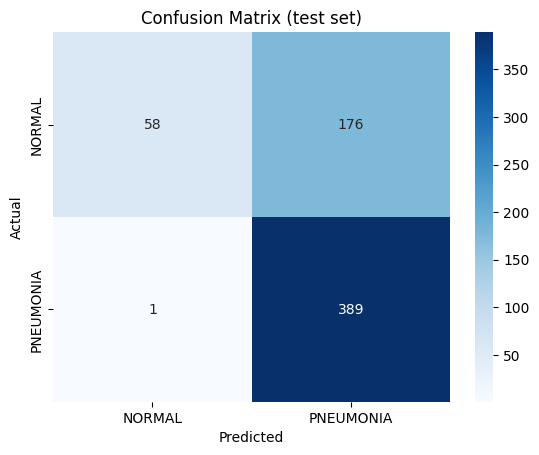

In [16]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (test set)')
plt.show()

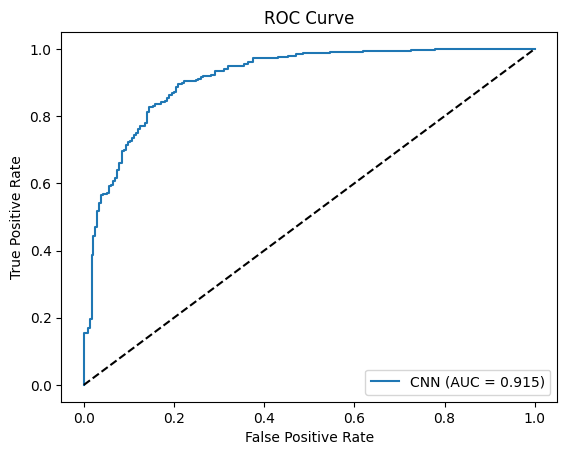

In [17]:
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.plot(fpr, tpr, label=f'CNN (AUC = {roc_auc_score(y_test, y_prob):.3f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

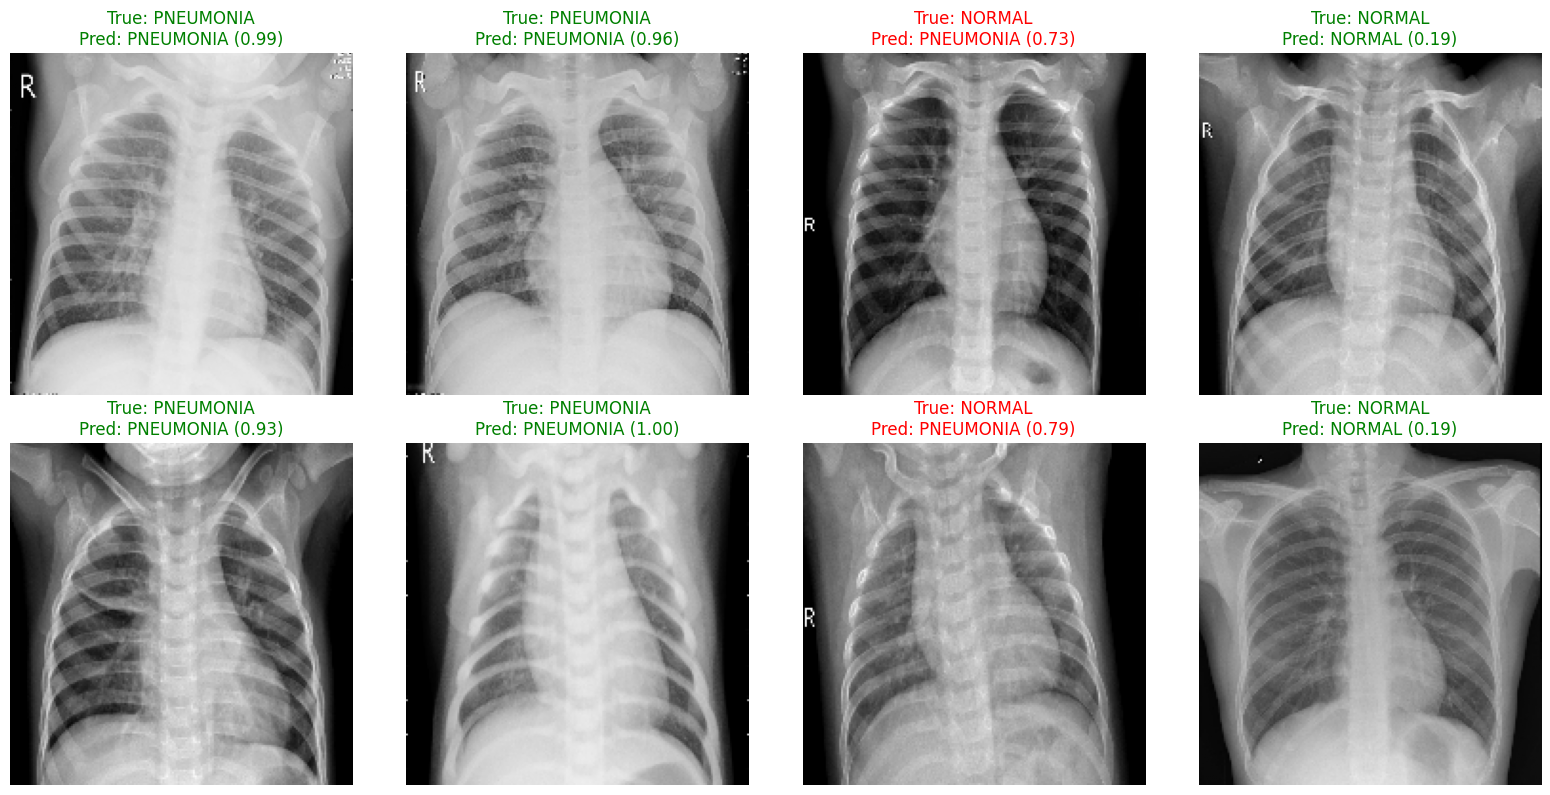

In [18]:
# a few test predictions, green = correct, red = wrong
idx = np.random.choice(len(test_df), 8, replace=False)
plt.figure(figsize=(16, 8))
for i, j in enumerate(idx):
    img, _ = load_image(test_df['path'].values[j], 0)
    plt.subplot(2, 4, i + 1)
    plt.imshow(img[:, :, 0], cmap='gray')
    true_lbl, pred_lbl = CLASSES[y_test[j]], CLASSES[y_pred[j]]
    plt.title(f'True: {true_lbl}\nPred: {pred_lbl} ({y_prob[j]:.2f})',
              color='green' if true_lbl == pred_lbl else 'red')
    plt.axis('off')
plt.tight_layout()
plt.show()

## 7. Conclusion

The CNN reached **71.6% accuracy** on the 624 test images, with a ROC-AUC of **0.915**. It found 389 of the 390 pneumonia cases (**99.7% recall**), but it also labelled 176 of the 234 normal X-rays as pneumonia, so only 25% of the normal images were classified correctly.

**Validation vs test.** The best model (epoch 7) scored 96.1% on the validation set but only 71.6% on the test set. The validation images were split randomly from the training folder, and the dataset has several X-rays from the same patients, so very similar images can end up in both training and validation. That makes the validation score too optimistic. The test folder contains different patients, so it is the more honest measure, and the gap shows the model has not yet generalised well to new patients.

**Why the errors go one way.** The ROC-AUC of 0.915 shows the model still ranks pneumonia images above normal ones most of the time. The main problem is that on the new test images its probabilities are pushed towards pneumonia, so at the 0.5 threshold most normal X-rays get flagged. For a screening tool this is the safer kind of mistake, since only 1 sick patient was missed, but this many false alarms would put too much extra work on doctors to be used in practice.

**Training limits.** The model was trained on a laptop CPU, where one epoch took about 15 minutes, so it was trained for only 8 epochs (about 2 hours). The validation results swung strongly between epochs (for example 96% at epoch 7 and 74% at epoch 8), which shows that training had not settled yet. A likely cause is that the Batch Normalization layers' running statistics had not stabilised in so few epochs, together with a fairly high learning rate of 0.001. ModelCheckpoint and EarlyStopping kept the best epoch (7), so the unstable last epoch did not affect the final model.

**Future improvements.** Train for more epochs on a GPU (for example on Kaggle or Google Colab) with a lower learning rate, split training and validation by patient instead of by image, and use transfer learning from a pretrained network such as ResNet50 or EfficientNet. Choosing the decision threshold on a validation set that better matches new patients would also reduce the false alarms.

## 8. Saving the Model and Inference

The best model is saved in joblib format. Then it is loaded back from the file and used to predict single X-ray images, the same way it would be used on a new patient's scan.

In [19]:
import joblib

joblib.dump(model, 'pneumonia_model.joblib')
print('Model saved to pneumonia_model.joblib')

Model saved to pneumonia_model.joblib


IM-0001-0001.jpeg: PNEUMONIA (pneumonia probability = 0.57)
person100_bacteria_475.jpeg: PNEUMONIA (pneumonia probability = 1.00)


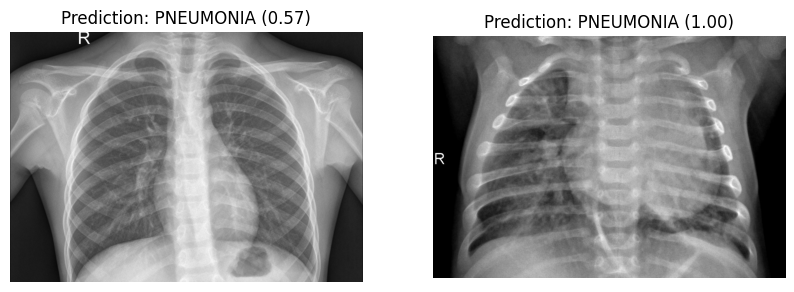

In [20]:
def predict_xray(image_path, cnn_model):
    img, _ = load_image(image_path, 0)   # same preprocessing as training (grayscale, 180x180, /255)
    prob = cnn_model.predict(tf.expand_dims(img, 0), verbose=0)[0][0]
    label = 'PNEUMONIA' if prob >= 0.5 else 'NORMAL'
    return label, prob


loaded_cnn = joblib.load('pneumonia_model.joblib')

# one normal and one pneumonia image from the test folder
examples = [test_df[test_df['label'] == 0]['path'].values[0],
            test_df[test_df['label'] == 1]['path'].values[0]]

plt.figure(figsize=(10, 5))
for i, path in enumerate(examples):
    label, prob = predict_xray(path, loaded_cnn)
    print(f'{os.path.basename(path)}: {label} (pneumonia probability = {prob:.2f})')
    plt.subplot(1, 2, i + 1)
    plt.imshow(plt.imread(path), cmap='gray')
    plt.title(f'Prediction: {label} ({prob:.2f})')
    plt.axis('off')
plt.show()